# Phase 4 — Alien physics and law discovery

Tycho now simulates central forces other than Newton's (power laws, Hooke, Yukawa, a GR-like
1/r³ term), N-body systems with hidden members, and kinematic paths that obey no force law
at all (a rectangle, a figure-eight). Jan gains non-Keplerian families
(`central-power-law`, `central-hooke`, `central-yukawa`, `central-newton-plus-inverse-cube`,
`perturbed-conic` — Le Verrier's model of an unseen planet), polygon/periodic kinematic paths,
law discovery (`discovery.sindy`, `discovery.pysr`) and physics-informed ML (`piml.ude`,
`piml.neural_ode`, `piml.hnn`). Rudolf scores the *structure* of the answer: symbolic and
numerical law errors, and whether a strategy honestly declines to claim a law.

In [1]:
import os, warnings
os.chdir('/home/dylan/Projects/jan-and-tycho')
os.environ.setdefault("MPLBACKEND", "Agg")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from pathlib import Path
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 160)

from IPython.display import Video
def results(name):
    p = Path("runs/sweeps") / name / "results.parquet"
    if not p.exists():
        print(f"(missing) run: jt bench sweep bench/{name}.yaml --workers 14 && jt bench report runs/sweeps/{name}")
        return None
    return pd.read_parquet(p)
def show(name, fig, width=760):
    p = Path("runs/sweeps") / name / "figures" / fig
    display(Image(filename=str(p), width=width)) if p.exists() else print(f"(missing figure {p})")
def cell_fig(name, scenario, label, fig, seed=0, width=760):
    """A per-run figure (or MP4) from a sweep cell."""
    p = Path("runs/sweeps") / name / "cells" / scenario / "base" / str(seed) / "rudolf" / label / "figures" / fig
    if not p.exists():
        print(f"(missing figure {p})")
    elif p.suffix == ".mp4":
        display(Video(str(p), embed=True, width=width))
    else:
        display(Image(filename=str(p), width=width))

## How a law is judged

* **Symbolic**: the recovered radial law f(r) is compared with the truth over the radii the
  orbit visits — *exact* (same function, constants included), *up to constants* (the same
  expression once its numbers are refitted), or *mismatch*.
* **Tolerance relative to Newton.** Several truths differ from Newton by very little (the
  GR-like term changes the field by ~2×10⁻⁴). A fixed tolerance would call plain Newton
  "exact" there, so a recovered law must be within 10⁻³ **and** within half of the truth's own
  departure from Newton — it has to explain at least half of what makes the truth non-Newtonian.
* **Hidden bodies.** When the truth is Newton plus an unseen planet there is no radial law to
  compare; a strategy that claims a perturber is judged by where it puts it (longitude
  within 10° at the epoch of maximum perturbation), others by their field.
* **Answer categories** (rejection matrix): correct law, right form (correct expression,
  wrong constants), wrong law, spurious law (a law claimed for a kinematic truth), kinematic
  or rejected (an honest refusal), nonparametric.

## Acceptance 1 — T0: discovery recovers 1/r² and Hooke's law exactly

T0 publishes noisy heliocentric positions (σ = 10⁻⁵ AU here). Both discovery strategies
regress the radial acceleration on a library of powers of r (SINDy: best-subset selection,
robust where powers of r are nearly collinear over a narrow range; PySR: symbolic
regression, Pareto front by complexity).

In [2]:
from tycho import load_scenario
from tycho.scenario import apply_overrides, Scenario
from jt_bench.harness import ensure_run, fit, score
import yaml
rows = []
for name in ["mars_like", "hooke_trap"]:
    data = yaml.safe_load(Path(f"scenarios/{name}.yaml").read_text())
    data = apply_overrides(data, {"knowledge_tier": "T0", "noise": [{"type": "position_gaussian", "sigma_au": 1e-5}]})
    run_dir = ensure_run(Scenario.model_validate(data), 0, run_dir=f"runs/notebooks/{name}_T0/0")
    for s in ["discovery.sindy", "discovery.pysr"]:
        sc = score(run_dir, fit(run_dir, s).label, plots=(s == "discovery.pysr"))["bodies"]["target"]["structural"]
        rows.append({"scenario": name, "strategy": s, "symbolic": sc["symbolic"], "rel. error": sc["symbolic_rel_error"]})
pd.DataFrame(rows)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


,scenario,strategy,symbolic,rel. error
0,mars_like,discovery.sindy,exact,0.000360
1,mars_like,discovery.pysr,up_to_constants,0.001591
2,hooke_trap,discovery.sindy,exact,0.000161
3,hooke_trap,discovery.pysr,exact,0.000161


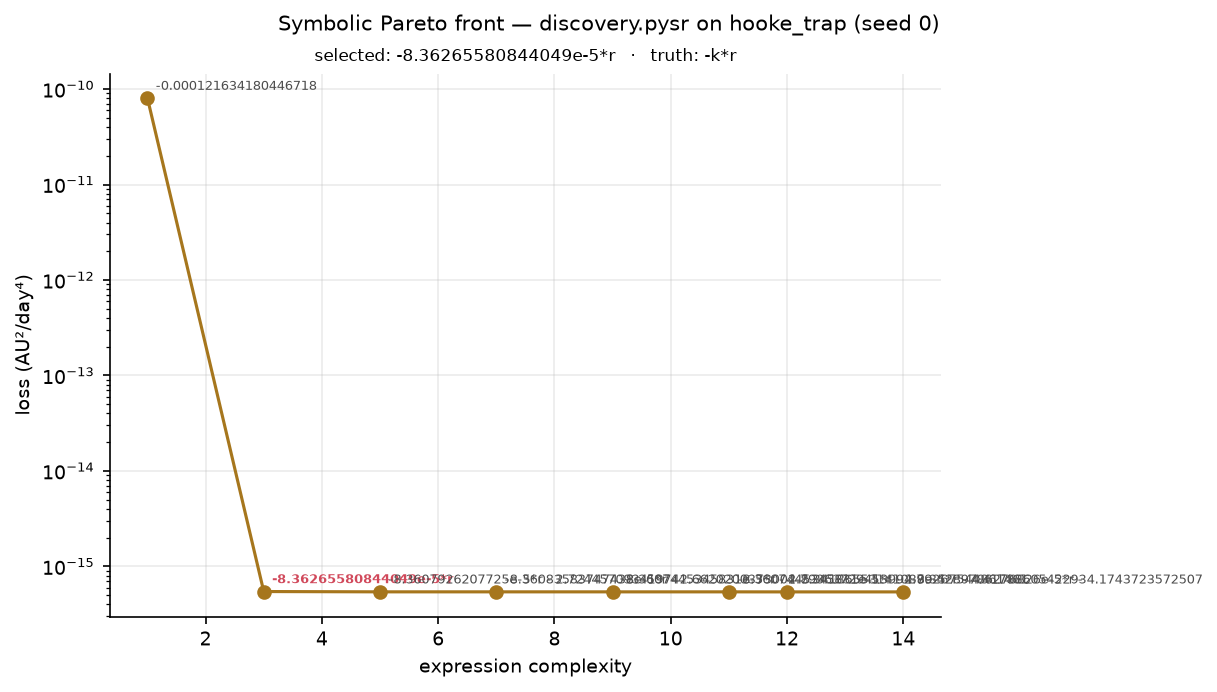

In [3]:
display(Image(filename="runs/notebooks/hooke_trap_T0/0/rudolf/discovery.pysr/figures/symbolic_pareto.png", width=700))

## The Phase 4 sweep

Seven scenarios × (classical.lsq with each dynamical family, `bayes.nested` over Newton /
power law / perturbed conic, `kepler.triangulate`, both discovery strategies and the three
PIML models) × 2 seeds, all at T1 (sky directions, known Earth).

In [4]:
df = results("phase4_alien_physics")
if df is not None:
    ok = df[df.status == "ok"]
    print(f"{len(df)} cells, {len(ok)} ok; failures:")
    display(df[df.status != "ok"][["scenario", "seed", "label", "status", "error"]])

182 cells, 181 ok; failures:


,scenario,seed,label,status,error
124,hidden_perturber,1,NaN,error,RuntimeError: no period with ≥ 2 repeats in th...


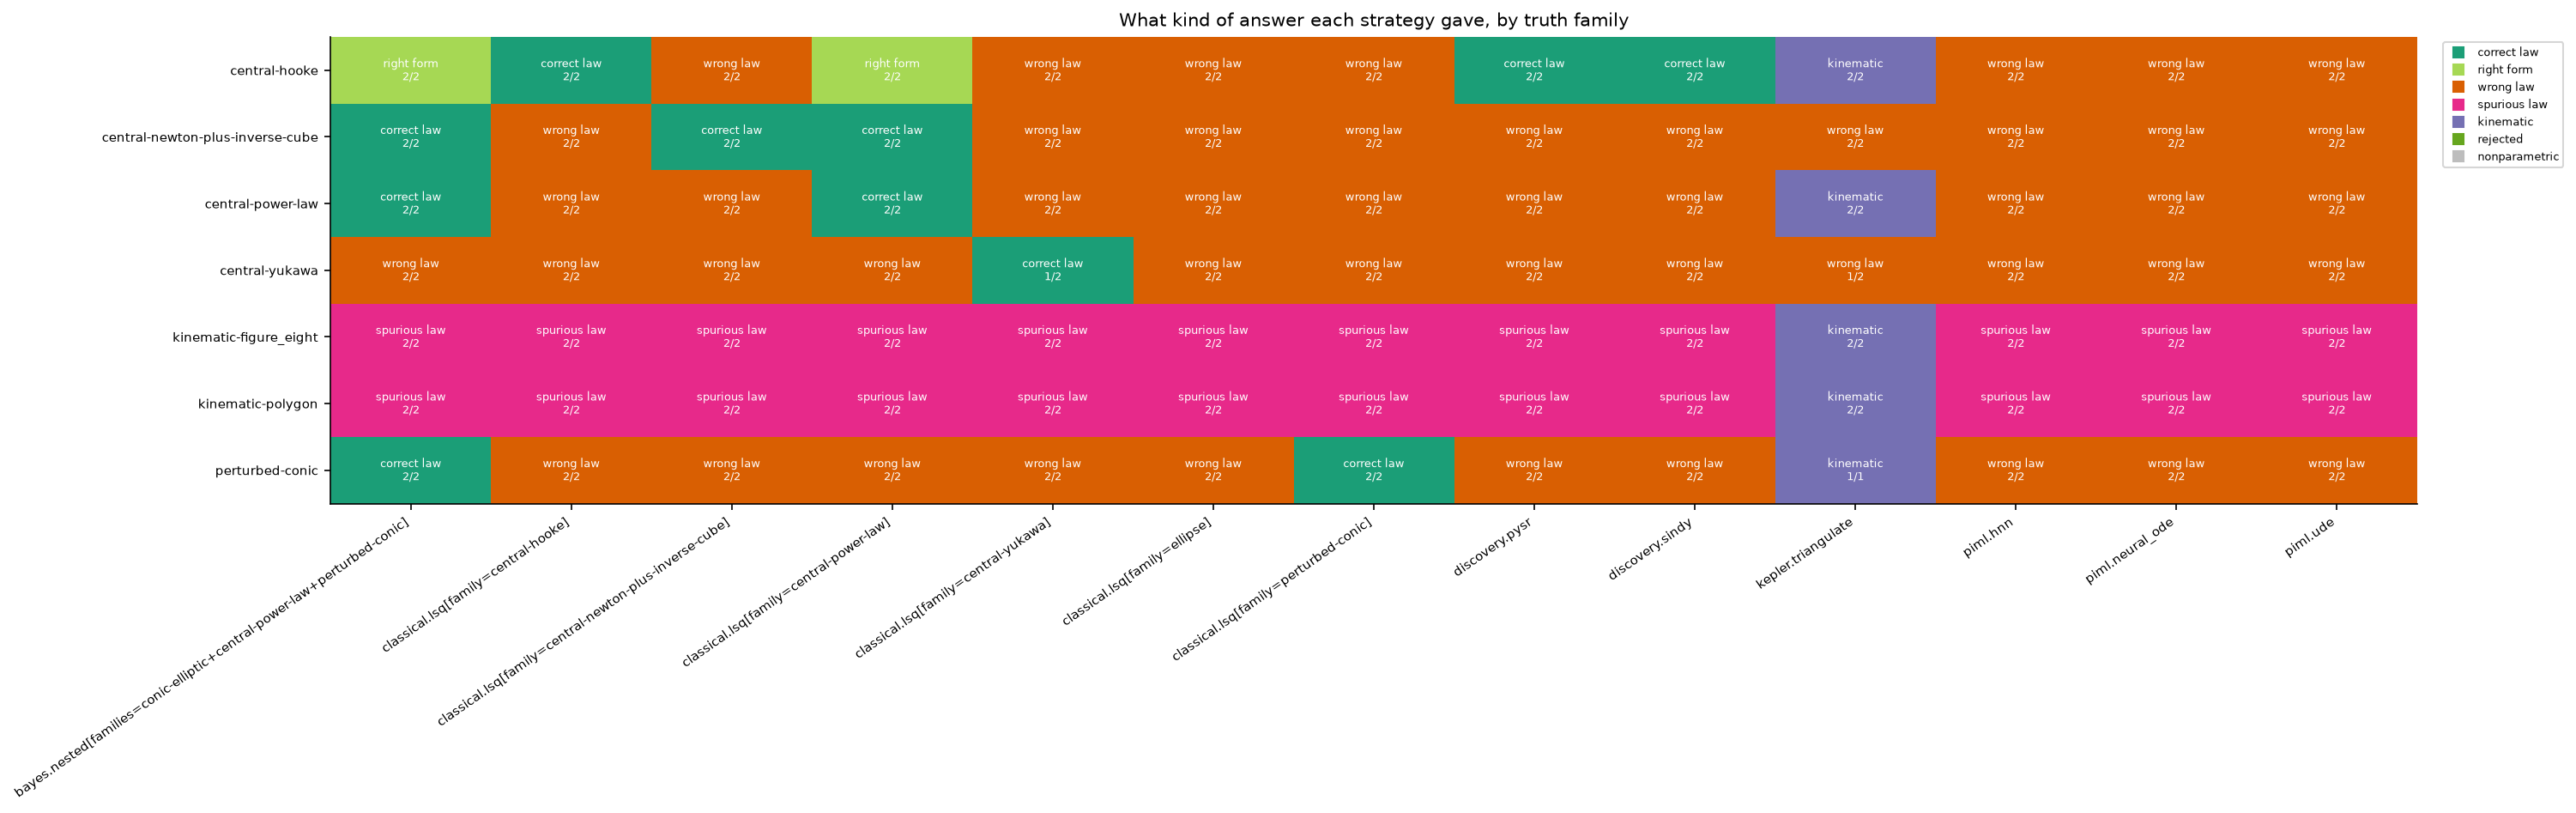

In [5]:
show("phase4_alien_physics", "rejection_matrix.png", 950)

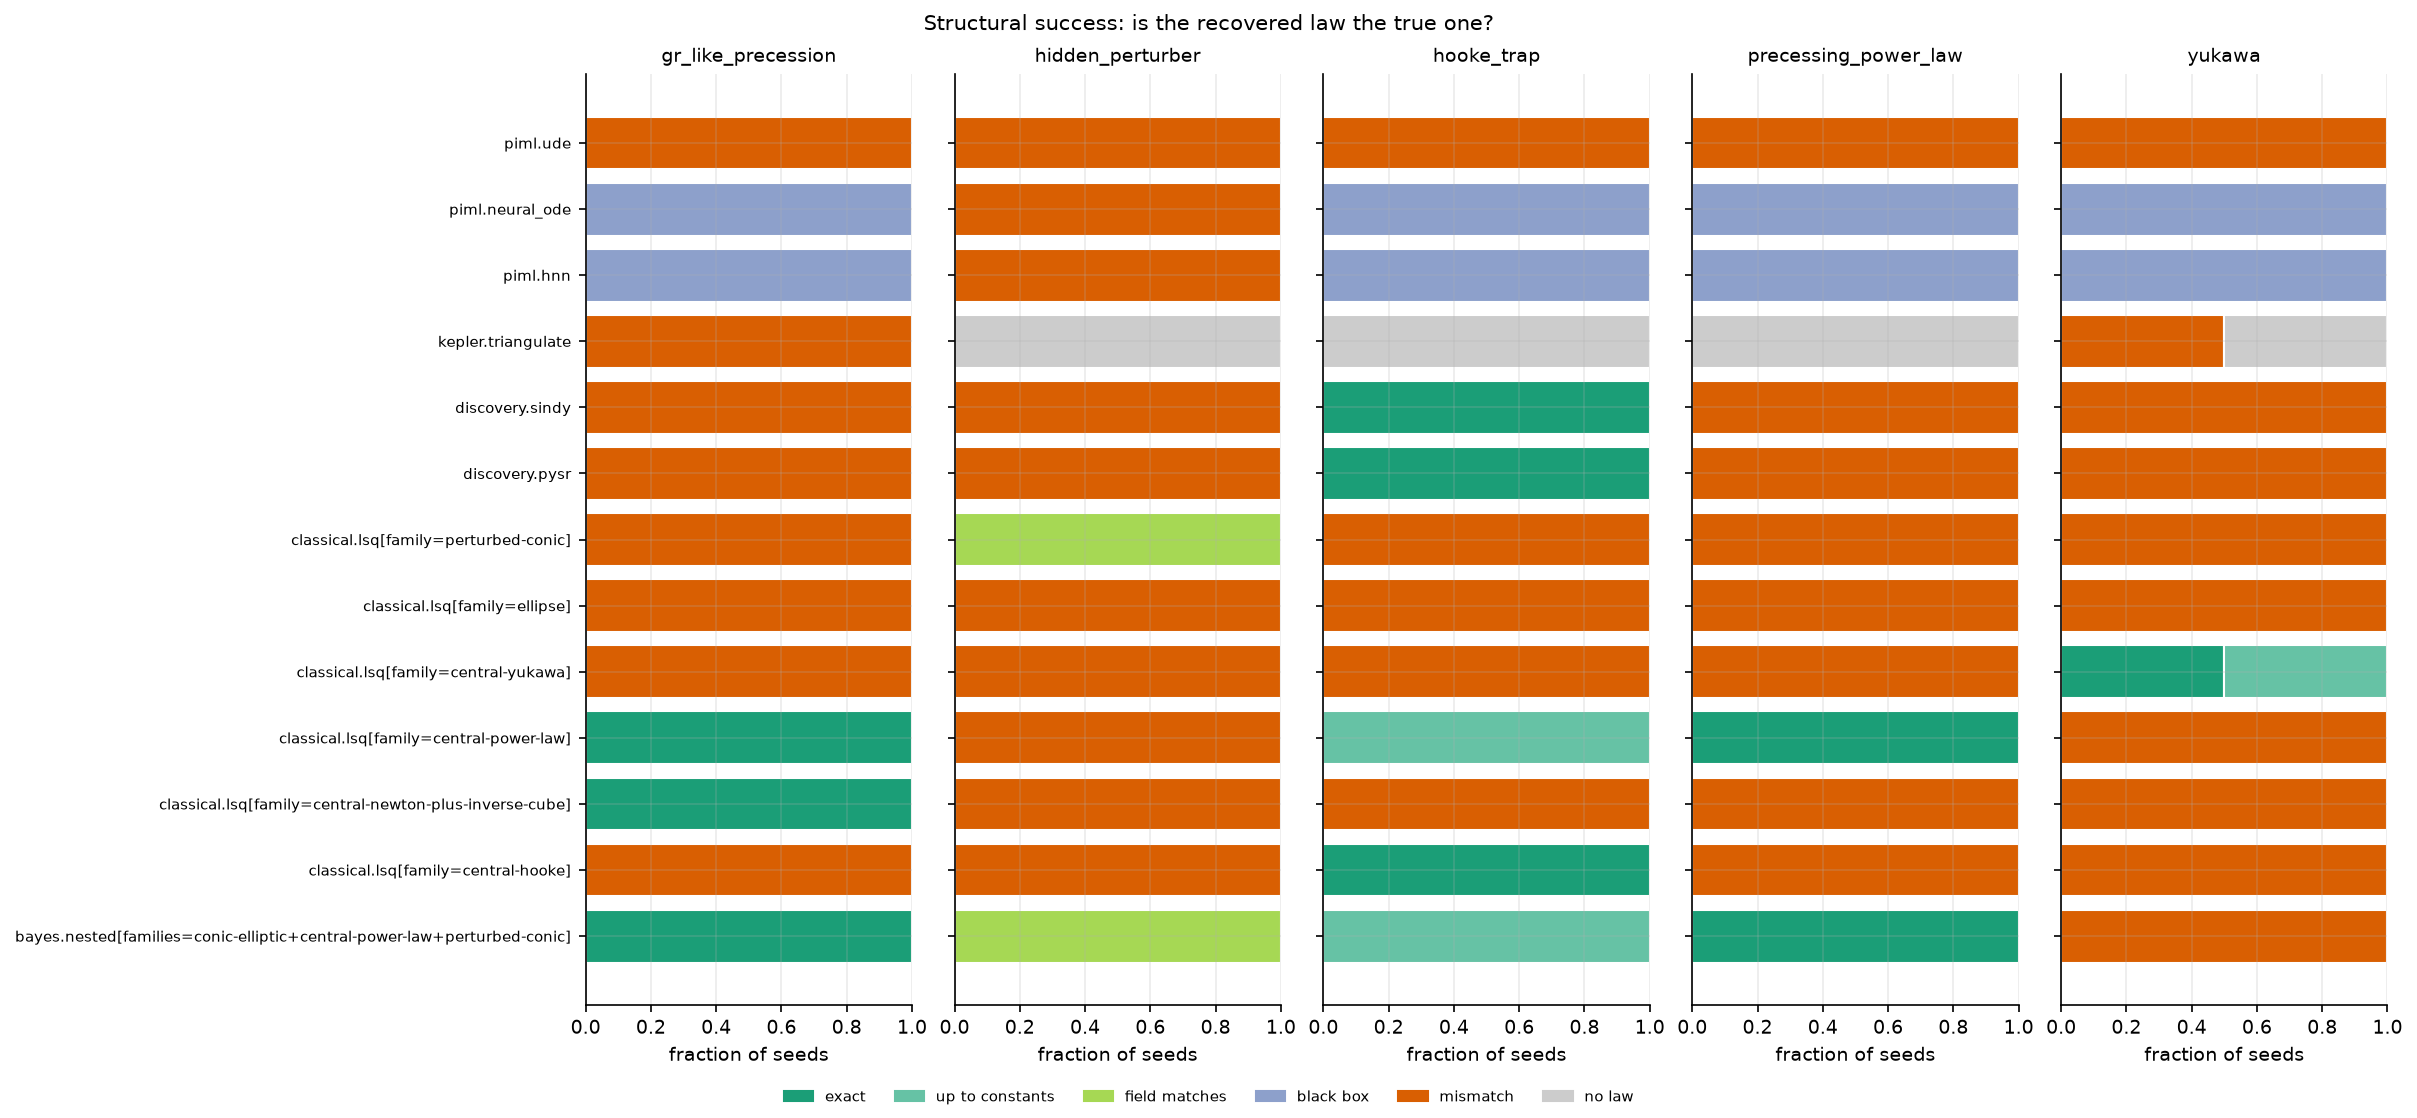

In [6]:
show("phase4_alien_physics", "structural_success.png", 950)

## Acceptance 2 — T1: the exponent of `precessing_power_law` within ±0.01

In [7]:
import json
if df is not None:
    rows = []
    for _, r in df[(df.scenario == "precessing_power_law") & (df.status == "ok")].iterrows():
        hyp = json.loads((Path("runs/sweeps/phase4_alien_physics") / r.run_dir / "jan" / r.label / "hypothesis.json").read_text())
        law = (hyp.get("law") or {})
        n = (law.get("constants") or {}).get("n")
        if n is not None:
            rows.append({"label": r.label, "seed": r.seed, "n": n, "|n − 2.05|": abs(n - 2.05)})
    display(pd.DataFrame(rows))

,label,seed,n,|n − 2.05|
0,classical.lsq[family=central-power-law],0,2.050010,0.000010
1,bayes.nested[families=conic-elliptic+central-p...,0,2.050010,0.000010
2,classical.lsq[family=central-power-law],1,2.050018,0.000018
3,bayes.nested[families=conic-elliptic+central-p...,1,2.050018,0.000018


The force-law figure shows f(r) and, more sharply, the local exponent n(r) = −d ln|f|/d ln r against the truth over the radii visited:

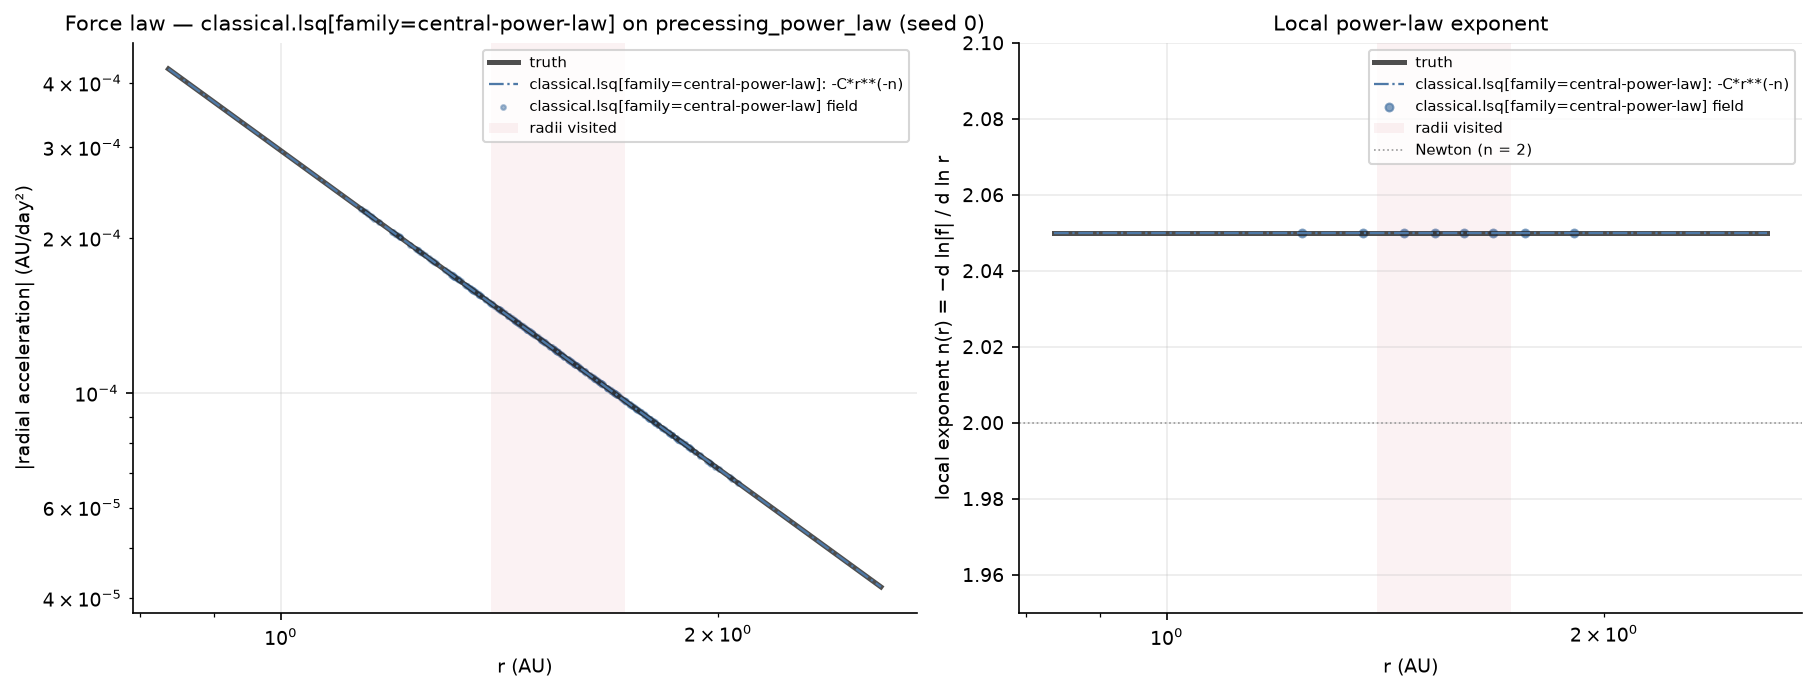

In [8]:
cell_fig("phase4_alien_physics", "precessing_power_law", "classical.lsq[family=central-power-law]", "force_law.png", width=950)

## Acceptance 3 — `hidden_perturber`: where is the unseen planet?

A Uranus-like body is pulled by an unseen Neptune-mass planet for 70 years. Criterion: the
hidden body's heliocentric longitude within 10° at the epoch of maximum perturbation, by
`piml.ude` or by `PerturbedConic` + `bayes.nested`.

**Note.** The perturber's *distance* is not identified: over a 70-year arc its pull is
nearly a tidal field, which depends on m/d³, so mass and distance trade off along a ridge;
the longitude — the direction of the pull — is well determined. (Le Verrier's prediction
had the same character: his assumed distance was too large, but Galle found Neptune within
about a degree of the predicted direction.) `piml.ude` with
`time_input` learns a time-dependent correction but does not localize a body; it is scored on
its field instead.

In [9]:
if df is not None:
    d = df[(df.scenario == "hidden_perturber") & (df.status == "ok")]
    cols = ["label", "seed", "hidden_longitude_error_deg", "hidden_distance_pred_au", "hidden_distance_true_au", "holdout_rms_arcsec", "selected_family", "p_true_family"]
    display(d[[c for c in cols if c in d]].dropna(subset=["hidden_longitude_error_deg"]))

,label,seed,hidden_longitude_error_deg,hidden_distance_pred_au,hidden_distance_true_au,holdout_rms_arcsec,selected_family,p_true_family
109,classical.lsq[family=perturbed-conic],0,0.273346,72.090252,29.877346,11.847398,NaN,NaN
110,bayes.nested[families=conic-elliptic+central-p...,0,0.273346,72.090252,29.877346,12.374712,perturbed-conic,1.0
122,classical.lsq[family=perturbed-conic],1,1.121090,72.642406,29.877346,23.958729,NaN,NaN
123,bayes.nested[families=conic-elliptic+central-p...,1,1.121090,72.642406,29.877346,23.112047,perturbed-conic,1.0


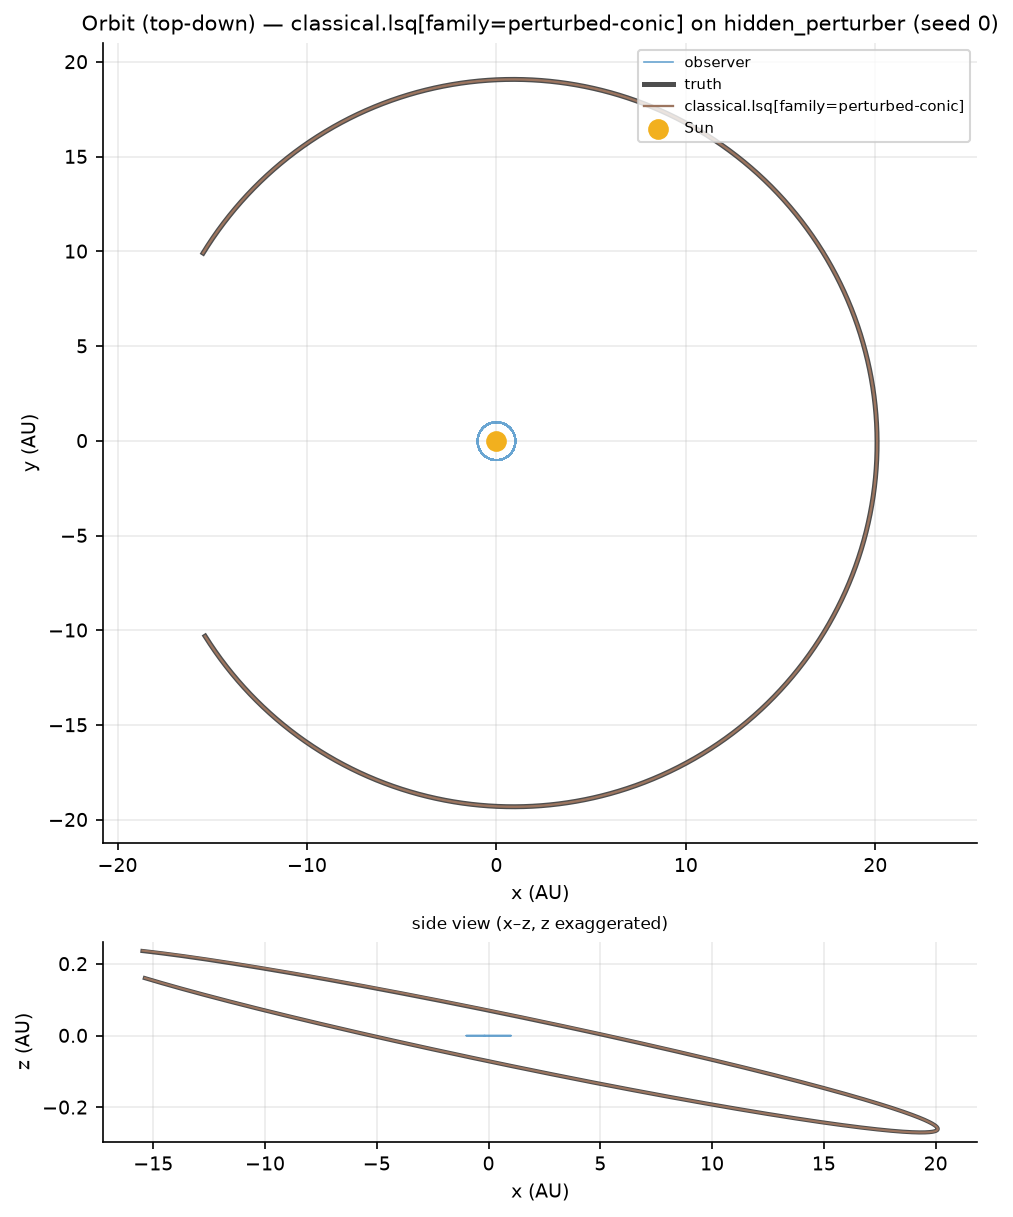

In [10]:
cell_fig("phase4_alien_physics", "hidden_perturber", "classical.lsq[family=perturbed-conic]", "orbit_topdown.png", width=700)

## Acceptance 4 — `rectangle`: vertices within 2 %, and an honest kinematic answer

`kepler.triangulate` finds the period (1500 d) from the sky track, triangulates positions
one period apart and finds no conic that fits them. It then fits a polygon: RDP proposes
corners, near-collinear and too-short edges are merged, and each vertex is the intersection
of neighbouring edge lines — so corners that always fall in observing gaps are still
recovered. The predicted path is chosen by cross-validation (phase-contiguous folds, since
neighbouring triangulated points share interpolated directions) among the polygon, a smooth
Fourier path and point-to-point interpolation.

In [11]:
if df is not None:
    d = df[(df.scenario.isin(["rectangle", "figure_eight"])) & (df.status == "ok")]
    display(d[["scenario", "label", "seed", "answer", "rejection_credit", "rejection_penalty", "vertex_error_frac", "traj_rms_holdout_au"]].sort_values(["scenario", "label", "seed"]))

,scenario,label,seed,answer,rejection_credit,rejection_penalty,vertex_error_frac,traj_rms_holdout_au
162,figure_eight,bayes.nested[families=conic-elliptic+central-p...,0,spurious law,False,True,NaN,3.146041
175,figure_eight,bayes.nested[families=conic-elliptic+central-p...,1,spurious law,False,True,NaN,2.713560
158,figure_eight,classical.lsq[family=central-hooke],0,spurious law,False,True,NaN,1.891108
171,figure_eight,classical.lsq[family=central-hooke],1,spurious law,False,True,NaN,2.462186
160,figure_eight,classical.lsq[family=central-newton-plus-inver...,0,spurious law,False,True,NaN,1.891412
173,figure_eight,classical.lsq[family=central-newton-plus-inver...,1,spurious law,False,True,NaN,2.487562
157,figure_eight,classical.lsq[family=central-power-law],0,spurious law,False,True,NaN,1.891604
170,figure_eight,classical.lsq[family=central-power-law],1,spurious law,False,True,NaN,2.369484
159,figure_eight,classical.lsq[family=central-yukawa],0,spurious law,False,True,NaN,35.351201
172,figure_eight,classical.lsq[family=central-yukawa],1,spurious law,False,True,NaN,2.427714


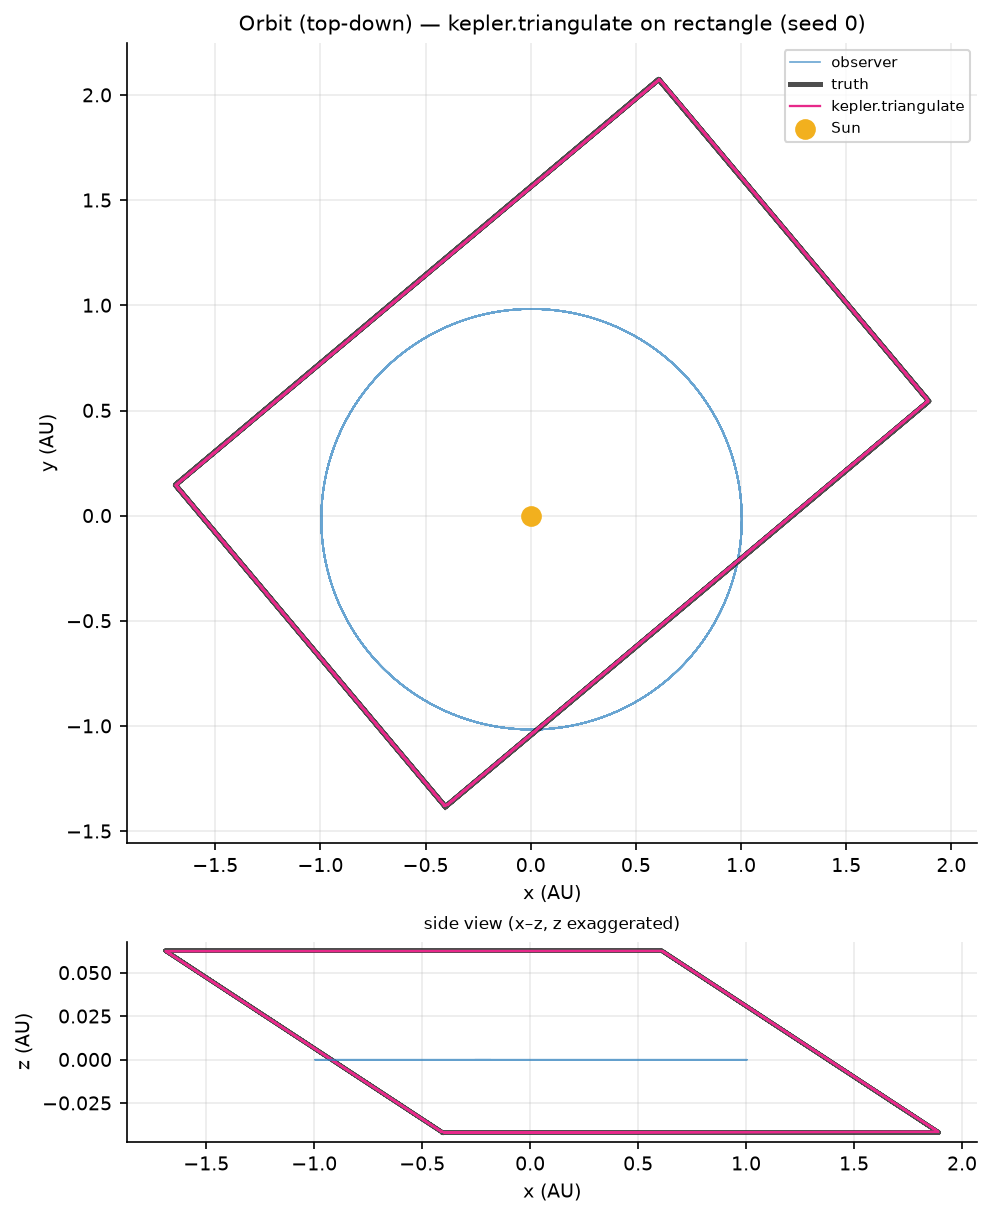

In [12]:
cell_fig("phase4_alien_physics", "rectangle", "kepler.triangulate", "orbit_topdown.png", width=700)

**Rejection credit.** A kinematic answer earns credit when it also predicts well: median
holdout sky error within 5σ, *or* holdout 3D path within 1 % of the orbit's size. The second
clause exists because the rectangle passes very close to the Earth's orbit, where a
0.005 AU path error is thousands of arcseconds on the sky.

## Known limitations

* `piml.neural_ode` and `piml.hnn` (black-box fields) are not accurate enough to integrate a
  20-year orbit: a small MLP pretrained to Newton matches it to ~10⁻³, while the sky data need
  ~10⁻⁶. They score as wrong laws with large holdout errors. `piml.ude` (Newton + a learned
  correction) does not have this problem.
* At T1, discovery strategies regress on positions from the best central-family fit, so they
  inherit that fit's bias; T0 is their native tier.